In [19]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
from google.colab import files
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image as keras_image

In [2]:
os.makedirs('model/caffe', exist_ok=True)
os.makedirs('images', exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f"Moved '{filename}' -> '{dest}'")

print("\nContents Of Images:")
print(os.listdir('images'))

Saving clock.jpg to clock.jpg
Saving elephant.jpg to elephant.jpg
Saving felfel-dolme.jpg to felfel-dolme.jpg
Moved 'clock.jpg' -> 'images/clock.jpg'
Moved 'elephant.jpg' -> 'images/elephant.jpg'
Moved 'felfel-dolme.jpg' -> 'images/felfel-dolme.jpg'

Contents Of Images:
['clock.jpg', 'elephant.jpg', 'felfel-dolme.jpg']


In [3]:
uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('model/caffe', filename)
  os.rename(filename, dest)
  print(f"Moved '{filename}' -> '{dest}'")

print("\nContents Of Model/Caffe:")
print(os.listdir('model/caffe'))

Saving bvlc_googlenet.caffemodel to bvlc_googlenet.caffemodel
Saving bvlc_googlenet.prototxt to bvlc_googlenet.prototxt
Saving synset_words.txt to synset_words.txt
Moved 'bvlc_googlenet.caffemodel' -> 'model/caffe/bvlc_googlenet.caffemodel'
Moved 'bvlc_googlenet.prototxt' -> 'model/caffe/bvlc_googlenet.prototxt'
Moved 'synset_words.txt' -> 'model/caffe/synset_words.txt'

Contents Of Model/Caffe:
['bvlc_googlenet.caffemodel', 'synset_words.txt', 'bvlc_googlenet.prototxt']


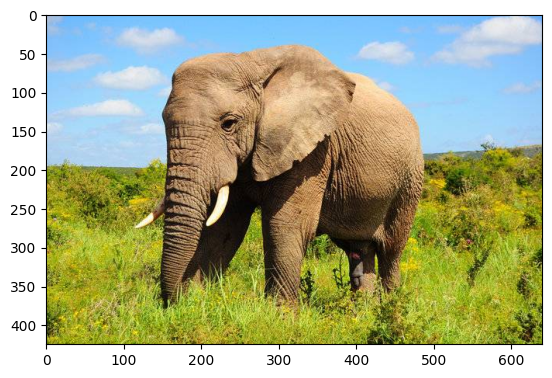

In [4]:
image = cv2.imread('images/elephant.jpg')
plt.imshow(image[..., ::-1])

In [14]:
print("Loading Pre-Trained Model (MobileNetV2)...")
model = MobileNetV2(weights='imagenet')
print("Model Loaded Successfully")
print(f"Model Input Shape: {model.input_shape}")

Loading Pre-Trained Model (MobileNetV2)...
14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model Loaded Successfully
Model Input Shape: (None, 224, 224, 3)


In [15]:
def predict(image_path, top_n=3):
  img = keras_image.load_img(image_path, target_size=(224, 224))
  img_array = keras_image.img_to_array(img)
  img_array = np.expand_dims(img_array, axis=0)
  img_array = preprocess_input(img_array)

  preds = model.predict(img_array, verbose=0)
  decoded_preds = decode_predictions(preds, top=top_n)[0]

  return img, decoded_preds

In [16]:
image_dir = 'images'
image_files = [f for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

if not image_files:
  print("No Images Found In 'images' Folder")
else:
  print(f"Found {len(image_files)} Image(s): {image_files}")

Found 3 Image(s): ['clock.jpg', 'elephant.jpg', 'felfel-dolme.jpg']


35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


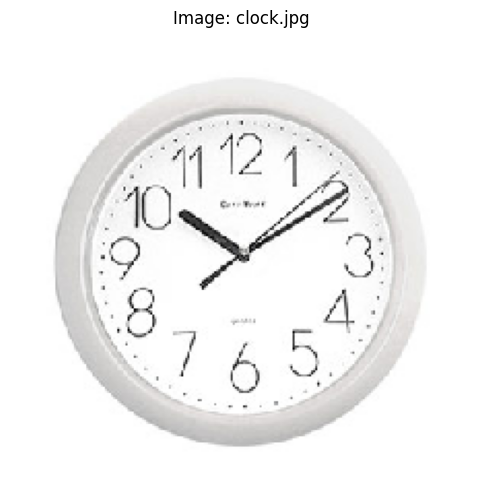


Top Predictions For 'clock.jpg':
1. wall_clock: 63.88%
2. analog_clock: 26.55%
3. stopwatch: 0.37%


In [17]:
if image_files:
  test_image = image_files[0]
  image_path = os.path.join(image_dir, test_image)

  img, predictions = predict(image_path, top_n=3)

  plt.figure(figsize=(8, 6))

  plt.imshow(img)
  plt.title(f"Image: {test_image}", fontsize=12)
  plt.axis('off')

  plt.show()

  print(f"\nTop Predictions For '{test_image}':")
  for i, (imagenet_id, label, score) in enumerate(predictions):
    print(f"{i+1}. {label}: {score*100:.2f}%")


Processing All 3 Image(s)



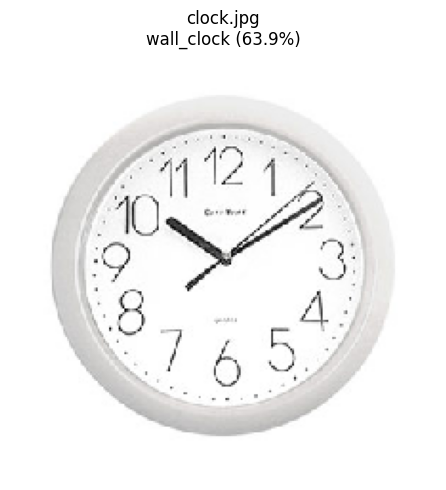

Image: clock.jpg
  1. wall_clock: 63.88%
  2. analog_clock: 26.55%
  3. stopwatch: 0.37%
----------------------------------------


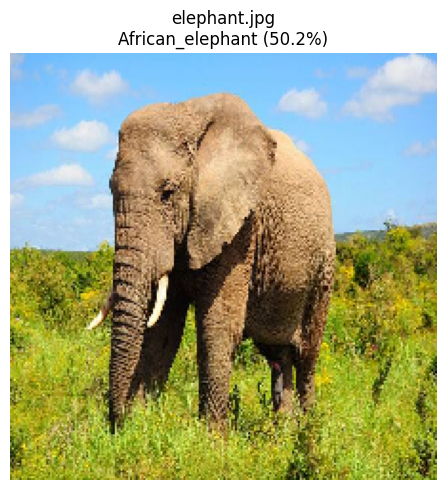

Image: elephant.jpg
  1. African_elephant: 50.16%
  2. tusker: 18.58%
  3. Indian_elephant: 13.31%
----------------------------------------


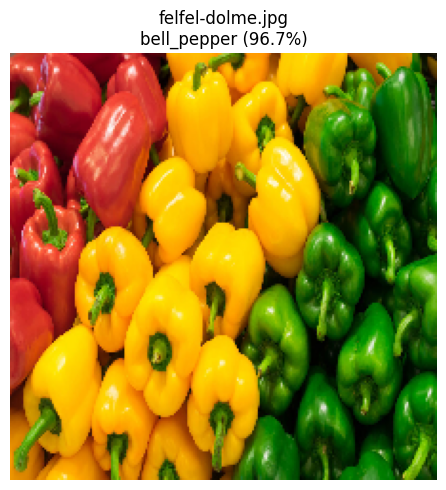

Image: felfel-dolme.jpg
  1. bell_pepper: 96.65%
  2. grocery_store: 0.37%
  3. corn: 0.21%
----------------------------------------


In [18]:
if image_files:
  print(f"\n{'='*60}")
  print(f"Processing All {len(image_files)} Image(s)")
  print(f"{'='*60}\n")

for img_file in image_files:
  image_path = os.path.join(image_dir, img_file)
  img, predictions = predict(image_path, top_n=3)

  plt.figure(figsize=(6, 5))

  plt.imshow(img)
  top_label = predictions[0][1]
  top_score = predictions[0][2] * 100
  plt.title(f"{img_file}\n{top_label} ({top_score:.1f}%)")
  plt.axis('off')

  plt.tight_layout()
  plt.show()

  print(f"Image: {img_file}")
  for i, (imagenet_id, label, score) in enumerate(predictions):
      print(f"  {i+1}. {label}: {score*100:.2f}%")
  print("-" * 40)